# 03 — Éléments finis 2D : pression de contact sous la bande de roulement

**Problème** : coupe transversale (y, z) de la bande de roulement au centre de l'empreinte, en
**déformation plane**, bicouche élastique linéaire (ceinture raide + gomme) posée sur une **fondation de
Winkler** en contact unilatéral.

**Formulation faible** : trouver $\mathbf u \in V$ tel que $\forall \mathbf v \in V_0$,
$$\int_\Omega \boldsymbol\sigma(\mathbf u):\boldsymbol\varepsilon(\mathbf v)\,d\Omega + \int_{\Gamma_c} k_w\,u_z v_z\,d\Gamma
= -\int_{\Gamma_{top}} p_i\,v_z\,d\Gamma - \int_{\Gamma_{ép}} q_s\,v_z\,d\Gamma$$
avec $\boldsymbol\sigma = \lambda\,\mathrm{tr}(\boldsymbol\varepsilon)\mathbf I + 2\mu\boldsymbol\varepsilon$.

**Conditions aux limites** : symétrie $u_y = 0$ en $y = 0$ (demi-modèle) ; face latérale libre ;
ressorts verticaux sous la gomme (compression seule) ; pression $p_i$ sur la face intérieure ; effort de
flanc $p_c\,b/2$ réparti sur une bande d'épaule de 5 cm.

**Éléments** : triangles P2 (quadratiques), qui limitent le verrouillage volumique pour ν = 0,45.

**Hypothèses fortes** : élasticité linéaire (le caoutchouc est hyperélastique, quasi incompressible),
pas de crampons, pas de courbure du sommet, pas de précontrainte de ceinture liée au gonflage, sol de
Winkler (pas de couplage latéral), propriétés matériaux = ordres de grandeur.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agritire import plotting
plotting.setup()
pd.set_option("display.precision", 3)

from agritire.fem_contact import (TreadSection, solve_section, winkler_modulus_from_bekker,
                                  full_width_profile, ROAD_FOUNDATION_MODULUS)
from agritire.soil import SOILS
sec = TreadSection()
kw_soil = winkler_modulus_from_bekker(SOILS["sandy_loam"], 140e3, sec.width)
print(f"k_w sol (limon sableux, sécant à 140 kPa) = {kw_soil:.2e} N/m³ ; route = {ROAD_FOUNDATION_MODULUS:.0e} N/m³")
print(f"raideur de la gomme E/h ≈ {sec.E_tread/sec.tread_thickness:.1e} N/m³")

k_w sol (limon sableux, sécant à 140 kPa) = 4.24e+06 N/m³ ; route = 1e+11 N/m³
raideur de la gomme E/h ≈ 1.5e+08 N/m³


## 1. Vérification : couche homogène sous charge uniforme (solution analytique exacte)

In [2]:
E, nu, p, kw = 6e6, 0.45, 100e3, 1e8
homog = TreadSection(E_tread=E, nu_tread=nu, E_belt=E, nu_belt=nu, n_y=10)
r = solve_section(homog, p, 0.0, kw)
expected = -p / kw - p * homog.height * (1 - nu**2) / E
print(f"pression de contact : min {r.pressure.min():.6f} Pa, max {r.pressure.max():.6f} Pa (attendu {p:.0f})")
print(f"u_z sommet : FEM {r.top_displacement:.9e} m ; analytique {expected:.9e} m")
print(f"équilibre : réactions {r.reaction:.6f} N/m ; appliqué {r.applied:.6f} N/m")

pression de contact : min 100000.000000 Pa, max 100000.000000 Pa (attendu 100000)
u_z sommet : FEM -1.691166667e-03 m ; analytique -1.691166667e-03 m
équilibre : réactions 32500.000000 N/m ; appliqué 32500.000000 N/m


Le champ exact ($\sigma_{zz} = -p$, $\sigma_{yy} = 0$) est linéaire en déplacement, donc reproduit
exactement par des éléments P2 : c'est un *patch test*. L'équilibre global est vérifié à la précision
machine (somme des réactions des ressorts = effort appliqué).

## 2. Maillage et déformée

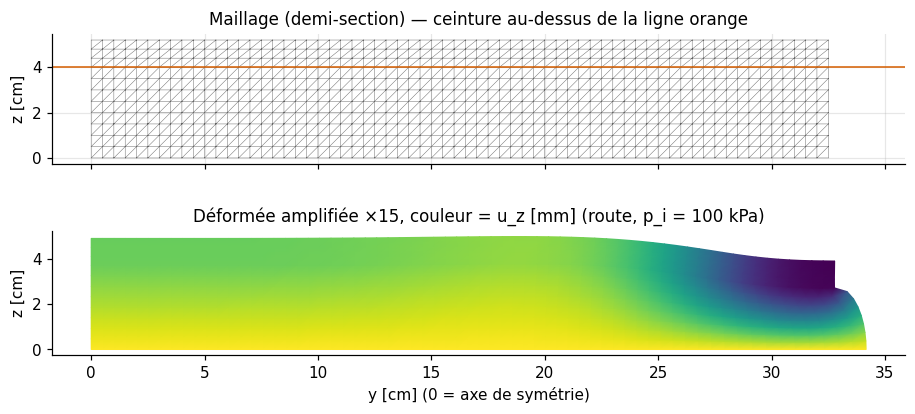

In [3]:
res = solve_section(sec, 100e3, 20e3, ROAD_FOUNDATION_MODULUS)
m = res.basis.mesh
u = res.displacement
ux = u[res.basis.nodal_dofs[0]]; uz = u[res.basis.nodal_dofs[1]]
scale = 0.25 * sec.height / np.abs(uz).max()
fig, axes = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True)
axes[0].triplot(m.p[0] * 100, m.p[1] * 100, m.t.T, lw=0.3, color="0.4")
axes[0].axhline(sec.tread_thickness * 100, color="C1", lw=1)
axes[0].set(ylabel="z [cm]", title="Maillage (demi-section) — ceinture au-dessus de la ligne orange")
axes[1].tripcolor((m.p[0] + scale * ux) * 100, (m.p[1] + scale * uz) * 100, m.t.T, uz * 1e3, shading="gouraud", cmap="viridis")
axes[1].set(xlabel="y [cm] (0 = axe de symétrie)", ylabel="z [cm]", title=f"Déformée amplifiée ×{scale:.0f}, couleur = u_z [mm] (route, p_i = 100 kPa)")
for ax in axes: ax.set_aspect("equal")
plotting.save(fig, "03_maillage_deformee");

## 3. Convergence en maillage

In [4]:
rows = []
for ny in (13, 26, 65, 130, 260):
    s_ = TreadSection(n_y=ny, n_z_tread=max(4, ny // 8))
    r_ = solve_section(s_, 100e3, 20e3, ROAD_FOUNDATION_MODULUS)
    rows.append(dict(n_y=ny, h_mm=1000 * s_.width / 2 / ny, pic_sur_moyenne=r_.peak_to_mean,
                     ddl=r_.basis.N))
conv = pd.DataFrame(rows); conv["ecart_vs_plus_fin_pct"] = 100 * (conv.pic_sur_moyenne / conv.pic_sur_moyenne.iloc[-1] - 1)
conv

,n_y,h_mm,pic_sur_moyenne,ddl,ecart_vs_plus_fin_pct
0,13,25.00,1.465,810,-12.660
1,26,12.50,1.613,1590,-3.834
2,65,5.00,1.665,6026,-0.753
3,130,2.50,1.675,20358,-0.133
4,260,1.25,1.678,73982,0.000


Le pic de pression converge (écart < 1 % pour $n_y = 65$, valeur retenue). Répartir l'effort de flanc
sur une bande de largeur finie est indispensable : appliqué sur une arête, il créerait une singularité
et un pic qui croîtrait indéfiniment avec le raffinement.

## 4. Pression de contact selon la pression de gonflage : route vs sol meuble

,support,p_i_kPa,p_moy_kPa,p_max_kPa,pic_sur_moyenne,iterations_ensemble_actif
0,route,60.0,80.0,162.258,2.028,1
1,route,120.0,140.0,219.391,1.567,1
2,route,240.0,260.0,341.925,1.315,1
3,sol meuble (limon sableux),60.0,80.0,134.711,1.684,1
4,sol meuble (limon sableux),120.0,140.0,189.090,1.351,1
5,sol meuble (limon sableux),240.0,260.0,297.846,1.146,1


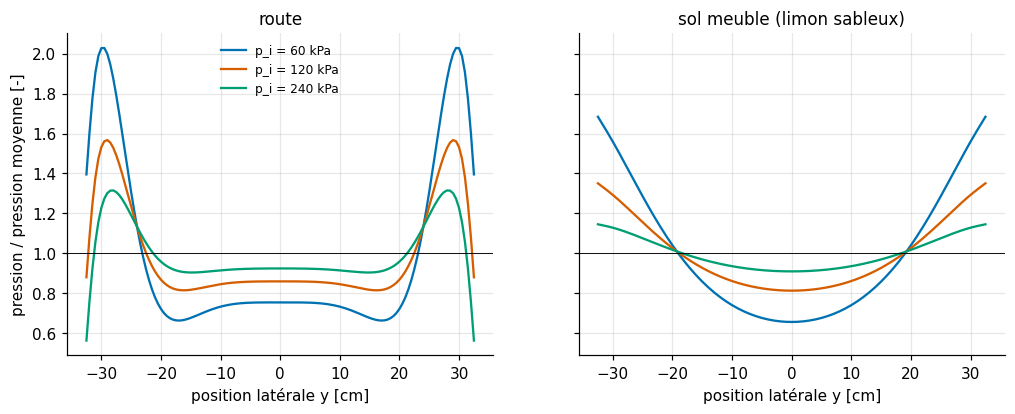

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
summary = []
for ax, (kw, lab) in zip(axes, ((ROAD_FOUNDATION_MODULUS, "route"), (kw_soil, "sol meuble (limon sableux)"))):
    for p_i in (60e3, 120e3, 240e3):
        r = solve_section(sec, p_i, 20e3, kw)
        y, pr = full_width_profile(r)
        ax.plot(y * 100, pr / r.mean_pressure, label=f"p_i = {p_i/1e3:.0f} kPa")
        summary.append(dict(support=lab, p_i_kPa=p_i / 1e3, p_moy_kPa=r.mean_pressure / 1e3,
                            p_max_kPa=r.pressure.max() / 1e3, pic_sur_moyenne=r.peak_to_mean,
                            iterations_ensemble_actif=r.iterations))
    ax.axhline(1, color="k", lw=0.6)
    ax.set(title=lab, xlabel="position latérale y [cm]")
axes[0].set_ylabel("pression / pression moyenne [-]"); axes[0].legend(fontsize=8)
plotting.save(fig, "03_pression_laterale")
pd.DataFrame(summary)

Lecture :
- la pression moyenne vaut exactement $p_i + p_c$ (équilibre), ce qui justifie l'hypothèse
  $p_g = p_i + p_c$ du module de terramécanique ;
- **à basse pression**, la part de charge portée par les flancs ($p_c$) est relativement plus grande :
  **surpression aux épaules** (≈ 2× la moyenne sur route à 60 kPa) ;
- **sur sol meuble**, le support déformable lisse la distribution (pic plus faible) : la ceinture
  répartit la charge sur une plus grande largeur quand le support est souple (longueur caractéristique
  de poutre sur fondation élastique $\lambda = (4EI/k)^{1/4}$).

## 5. Couplage FEM → usure : profil latéral d'usure
On découpe la largeur en bandes, chacune portant $w_i\,p(x)$ (poids issus du FEM sur route), avec un
glissement commun (ceinture rigide).

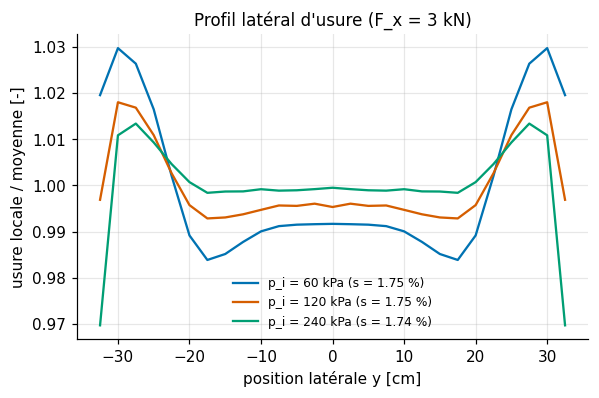

In [6]:
from agritire.wear import lateral_wear_profile
from scipy.interpolate import interp1d
fig, ax = plt.subplots(figsize=(6, 3.6))
for p_i in (60e3, 120e3, 240e3):
    r = solve_section(sec, p_i, 20e3, ROAD_FOUNDATION_MODULUS)
    y, pr = full_width_profile(r)
    yc = np.linspace(-sec.width / 2, sec.width / 2, 27)
    weights = interp1d(y, pr)(yc)
    s, wear = lateral_wear_profile(30e3, sec.width, p_i + 20e3, 3e3, weights)
    ax.plot(yc * 100, wear / wear.mean(), label=f"p_i = {p_i/1e3:.0f} kPa (s = {100*s:.2f} %)")
ax.set(xlabel="position latérale y [cm]", ylabel="usure locale / moyenne [-]", title="Profil latéral d'usure (F_x = 3 kN)")
ax.legend(fontsize=8)
plotting.save(fig, "03_profil_usure_lateral");

**Résultat non trivial** : malgré une surpression de 2× aux épaules, le profil d'usure ne varie que de
quelques %. Avec un glissement uniforme, une bande plus chargée a une limite d'adhérence $\mu p$ plus
haute, donc une zone glissante plus courte ; les deux effets se compensent presque.

Conclusion d'ingénieur : dans ce cadre, **la distribution de pression seule n'explique pas l'usure
irrégulière** épaules/centre observée en pratique. Il faudrait modéliser ce qui fait varier le
**glissement** dans la largeur : rayon de roulement local (courbure du sommet), dérive, carrossage,
mouvement des crampons. C'est une limite explicite du modèle, pas un résultat à extrapoler.